<a href="https://colab.research.google.com/github/ananya-0808/MLxFinanceChallenge/blob/main/Ananya_Jaiswal_2026_KWK_ML_x_Finance_Challenge_Final_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# [Title of Your Project]
**Your name:** Ananya Jaiswal  |  **Starter dataset or your own?** Own, from Kaggle

---

## How to use this template
- **Make a copy** (File > Save a copy in Drive) before you start.
- Every section marked **REQUIRED** must be filled in. That's what makes your project complete.
- Sections marked **OPTIONAL** are ways to make your project shine. Skip them if you're short on time.
- Sections 1-3 come straight from your Checkpoint 3 answers. Copy them in and update anything that changed.

### Minimum viable project checklist
A complete project has all of these:
- [ ] One dataset (Section 2)
- [ ] One model compared against a baseline (Sections 5-7)
- [ ] One evaluation metric (Section 7)
- [ ] A fairness check (Section 8)
- [ ] Every REQUIRED section of this template filled in
- [ ] Slides (15 or fewer) and a 5-7 minute video (Section 13)

---
## Agreement for written sections
By filling in the written sections of this notebook (Sections 1, 9, 10, and 11), you confirm that **you did not use AI tools or large language models (LLMs) to write their text**. These sections should be your own reasoning in your own words. AI use anywhere else should be recorded in Section 12.

---
## 1. Research question (REQUIRED)
**Instructions:** In 1-3 sentences, what finance question are you answering, and who would care about the answer?

Question: Which characteristics of medical insurance claims are most associated with fraud?

Who would care about this: Patients, Insurance companies, Hospitals

**What I'm predicting (target variable):** I will be predicting which characteristic of medical insurance that is the most associated with medical fraud.

**Is this a classification problem (predicting a category) or a regression problem (predicting a number)?** Classification, since I will be using data to analyze which characteristic is the most relevant to medical insurance fraud.

---
## 2. Dataset (REQUIRED)
**Instructions:** Fill in the table. If you used more than one dataset, add a row for each.

| Dataset name | Link / source | # of rows | Why I chose it |
|---|---|---|---|
| [Name] | [Link] | [Rows] | [1 sentence] |

In [2]:
# Load your data.
import pandas as pd

# Option A: a starter dataset. Paste its loading code from the Starter Datasets page here.

# Option B: your own CSV file. Replace the path below.
# df = pd.read_csv("path/to/your/file.csv")

df = pd.read_csv("healthcare_fraud_detection.csv")
df.head()

,Provider_ID,Claim_ID,Patient_Age,Patient_Gender,Diagnosis_Code,Procedure_Code,Claim_Amount,Approved_Amount,Insurance_Type,Claim_Submission_Date,Days_Between_Service_and_Claim,Number_of_Claims_Per_Provider_Monthly,Provider_Specialty,Patient_State,Claim_Status,Is_Fraud,Length_of_Stay,Visit_Type,Chronic_Condition_Flag,Prior_Visits_12m
0,P0052,C0000000,37,Male,I25.10,36415,443.51,393.16,Medicaid,2024-09-01,13,70,Cardiology,NY,Approved,0,0,Outpatient,1,2.0
1,P0121,C0000001,21,Female,E11.9,99213,467.50,461.33,Self-Pay,2022-09-05,5,62,General Practice,IL,Pending,0,5,Inpatient,1,2.0
2,P0140,C0000002,78,Female,J06.9,93000,591.69,530.06,Medicaid,2022-04-11,29,60,Cardiology,IL,Pending,0,5,Inpatient,1,3.0
3,P0202,C0000003,65,Male,I10,93000,235.15,189.11,Private,2023-10-11,22,70,General Practice,TX,Approved,0,0,Emergency,0,5.0
4,P0135,C0000004,36,Male,M54.5,85025,487.96,369.91,Private,2023-09-05,21,67,Pulmonology,PA,Approved,0,5,Inpatient,0,4.0


---
## 3. Data cleaning (REQUIRED)
**Instructions:** Clean your data in the code cell below (for example: fill or drop missing values, drop columns you don't need, convert text categories to numbers). Then list what you changed and why.

1. I will be dropping the Provider_ID because there is no reason for it to have any affect on medical fraud, since it is just an identification number for the patient.
2. For that same reason I will also be dropping the Claim_ID, Diagnosis_Code, and Procedure_Code.
3. Because Prior_Visits has some missing values, I will be using the median value, since it is resistant to outliers, and will hopefully not bias predictions too much.
4. Insurance_Type has 350 values missing, which is a good chunk of values, so instead of removing it, I will still keep it, but I will replace the missing values with N/A. This will also go for Provider_Specialty.

In [3]:
# Check for missing values and data types first.

# TODO: clean your data here.

# This drops the stated columns
df = df.drop(columns = ['Provider_ID'], errors = 'ignore')
df = df.drop(columns = ['Claim_ID'], errors = 'ignore')
df = df.drop(columns = ['Diagnosis_Code'], errors = 'ignore')
df = df.drop(columns = ['Procedure_Code'], errors = 'ignore')

# This changes Prior_Visits as described above
df['Prior_Visits_12m'] = pd.to_numeric(df['Prior_Visits_12m'], errors='coerce')
median_visits = df['Prior_Visits_12m'].median()
df['Prior_Visits_12m'] = df['Prior_Visits_12m'].fillna(median_visits)

# Fills N/A for all unavailable values in Insurance_Type
df['Insurance_Type'] = df['Insurance_Type'].fillna("N/A")
df['Provider_Specialty'] = df['Provider_Specialty'].fillna("N/A")

df.info()



<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 16 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   Patient_Age                            10000 non-null  int64  
 1   Patient_Gender                         10000 non-null  object 
 2   Claim_Amount                           10000 non-null  float64
 3   Approved_Amount                        10000 non-null  float64
 4   Insurance_Type                         10000 non-null  object 
 5   Claim_Submission_Date                  10000 non-null  object 
 6   Days_Between_Service_and_Claim         10000 non-null  int64  
 7   Number_of_Claims_Per_Provider_Monthly  10000 non-null  int64  
 8   Provider_Specialty                     10000 non-null  object 
 9   Patient_State                          10000 non-null  object 
 10  Claim_Status                           10000 non-null  object 
 11  Is_

---
## 4. Exploring the data (REQUIRED)
**Instructions:** Include at least one chart from your EDA (you can reuse your Checkpoint 3 work). Under it, write 1-2 sentences about what it shows.

[What the chart shows]

Patient_Gender
Female    50.01
Male      49.99
Name: proportion, dtype: float64


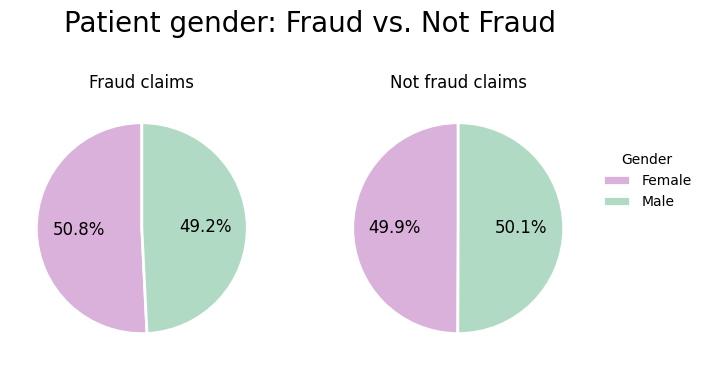

In [4]:
# TODO: make at least one chart (for example, a histogram, box plot, or bar chart of your target variable).

import matplotlib.pyplot as plt
import seaborn as sns

# For Patient_Gender, Insurance_Type, Provider_Speciality, Claim_Status, and Visit_Type, I will make pie charts to see if there are vast
# differences, along with fraud rates instead of fraud counts, since otherwise fraud counts might show up incredibly small

#Patient Gender
counts = pd.crosstab(df["Patient_Gender"], df["Is_Fraud"])
labels = counts.index.tolist()
colors = ["#DAB1DA", "#B1DAC5"][:len(labels)]

percents = df["Patient_Gender"].value_counts(normalize=True) * 100
print(percents.round(2))

fig, axes = plt.subplots(1, 2, figsize=(8, 4.5))

for ax, (flag, name) in zip(axes, [(1, "Fraud claims"), (0, "Not fraud claims")]):
    ax.pie(counts[flag], colors=colors, startangle=90,
           autopct="%1.1f%%",
           wedgeprops=dict(edgecolor="white", linewidth=2),
           textprops=dict(color="black", fontsize=12))
    ax.set_title(name)

fig.suptitle("Patient gender: Fraud vs. Not Fraud", fontsize=20)
fig.legend(labels, title="Gender", loc="center left", bbox_to_anchor=(0.85, 0.6), frameon=False)
plt.subplots_adjust(right=0.85)
plt.show()

These pie charts compare the gender breakdown of Fraud and Not Fraud Claims. The pie chart on the left shows that out of the claims flagged for fraud, **50.8%** of them were filed by women, and **49.2%** were filed by men. Similarily, the pie chart on the right shows that out of the claims not flagged for fraud, **49.9%** were filed by women and **50.1%** were filed by men. The numbers are incredibly close, which means that gender plays an incredibly small role in insurance fraud.

An aditional factor to note is that the gender is pretty evenly split with 5001 males and 4999 females, so there shouldn't be an overepresentation of any gender. In the real world, there might not be such an even split, so an overrepresentation of one gender needs to be taken into account when making conclusions.

Insurance_Type
Medicare    24.25
Medicaid    24.19
Private     24.05
Self-Pay    24.01
N/A          3.50
Name: proportion, dtype: float64


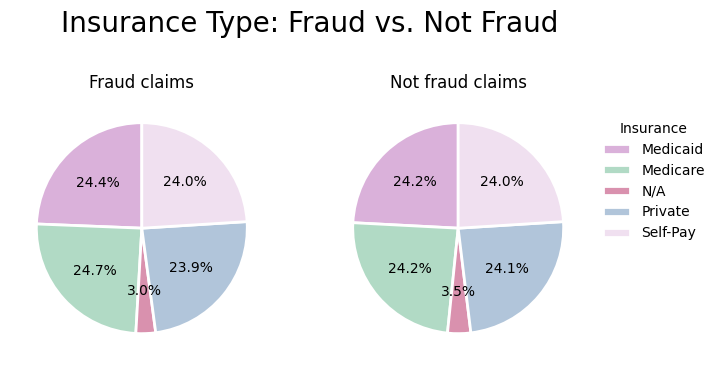

In [5]:
# Insurance Type
counts = pd.crosstab(df["Insurance_Type"], df["Is_Fraud"])
labels = counts.index.tolist()
colors = ["#DAB1DA", "#B1DAC5", "#D991AE", "#B1C5DA", "#F0E0F0"][:len(labels)]

percents = df["Insurance_Type"].value_counts(normalize=True) * 100
print(percents.round(2))

fig, axes = plt.subplots(1, 2, figsize=(8, 4.5))

for ax, (flag, name) in zip(axes, [(1, "Fraud claims"), (0, "Not fraud claims")]):
    ax.pie(counts[flag], colors=colors, startangle=90,
           autopct="%1.1f%%",
           wedgeprops=dict(edgecolor="white", linewidth=2),
           textprops=dict(color="black", fontsize=10))
    ax.set_title(name)

fig.suptitle("Insurance Type: Fraud vs. Not Fraud", fontsize=20)
fig.legend(labels, title="Insurance", loc="center left", bbox_to_anchor=(0.85, 0.6), frameon=False)
plt.subplots_adjust(right=0.85)
plt.show()

This pie chart compares the insurance type breakdown of Fraud and Not Fraud Claims. Because there were 350 missing values in this dataset, I replaced the empty values with N/A. The pie chart on the left shows that out of the claims flagged for fraud, **24.7%** of the patients had Medicare as the insurance company, **24.4%** had Medicaid, **24.0%** were self-paid, **23.9%** were private, and **3%** of them are unknown. Similarily, the pie chart on the right shows that out of the claims not flagged for fraud, **24.2%** of the patients had Medicare as the insurance company, **24.2%** had Medicaid, **24.0% **were self-paid, **24.1%** were private, and **3.5%** of them are unknown. The numbers within each pie chart are similar to each other and within 1% of each other (except for N/A, but that is a substitute for missing values, not an actual insurance type), which means that insurance type plays an small role in insurance fraud.

An additional factor to take note of is that here the insurance types are roughly equal in percentages, with each of the 4 categories making up about 24% of the total insurance (the remaining 3.5% is due to the unknown values). This ensures that there is no overepresentation of a single insurance type, however, does not accurately represent the real world, where one insurance type might be more popular than another. This is something that should be taken into account when analyzing the data.

Provider_Specialty
Internal Medicine    20.19
General Practice     18.78
Orthopedics          16.16
Neurology            15.16
Cardiology           13.66
Pulmonology          12.55
N/A                   3.50
Name: proportion, dtype: float64


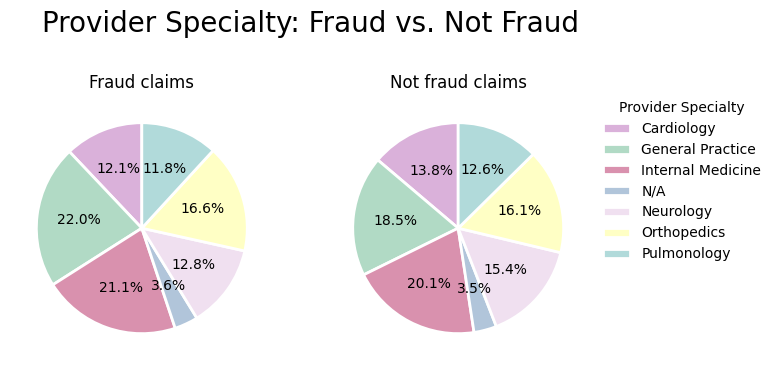

In [6]:
# Provider Specialty
counts = pd.crosstab(df["Provider_Specialty"], df["Is_Fraud"])
labels = counts.index.tolist()
colors = ["#DAB1DA", "#B1DAC5", "#D991AE", "#B1C5DA", "#F0E0F0", "#FFFFC5", "#B1DADA"][:len(labels)]

percents = df["Provider_Specialty"].value_counts(normalize=True) * 100
print(percents.round(2))

fig, axes = plt.subplots(1, 2, figsize=(8, 4.5))

for ax, (flag, name) in zip(axes, [(1, "Fraud claims"), (0, "Not fraud claims")]):
    ax.pie(counts[flag], colors=colors, startangle=90,
           autopct="%1.1f%%",
           wedgeprops=dict(edgecolor="white", linewidth=2),
           textprops=dict(color="black", fontsize=10))
    ax.set_title(name)

fig.suptitle("Provider Specialty: Fraud vs. Not Fraud", fontsize=20)
fig.legend(labels, title="Provider Specialty", loc="center left", bbox_to_anchor=(0.85, 0.6), frameon=False)
plt.subplots_adjust(right=0.85)
plt.show()

This pie chart compares the Provider Specialty breakdown of Fraud and Not Fraud Claims. Because there were 350 missing values in this dataset, I replaced the empty values with N/A instead of removing them, because I worried that it might affect the data. The pie chart on the left shows that out of the claims flagged for fraud, **12.1%** of the patients worked with cardiology, **11.8%** worked with Pulmonology, **16.6%** worked with Orthopedics, **12.8%** worked with Neurology, **21.1%** of them worked with Internal Medicine, **22.0%** of them worked with General Practice and **3.6%** of them are unknown. Similarily, the pie chart on the right shows that out of the claims not flagged for fraud, **13.8%** of the patients worked with cardiology, **12.6%** worked with Pulmonology, **16.1%** worked with Orthopedics, **15.4%** worked with Neurology, **20.1%** of them worked with Internal Medicine, **18.5%** of them worked with General Practice and **3.5%** of them are unknown.

While some of the numbers are close, there are some notable differences in some specialties. For example, General Practice has a 3% difference between Fraud Claims and Not Fraud Claims, which means that there is a possibility of a linkage between Provider Specialty and Fraud, although the difference might be too small to prove anything. Another thing to note is that General Practice is the most common specialty, with 20.2% of patients using that provider, which means that there is a possibility of overrepresenting that specialty, albeit a small possibility because it doesn't have a significantly higher rate than the other providers.

Claim_Status
Approved    70.53
Rejected    17.48
Pending     11.99
Name: proportion, dtype: float64


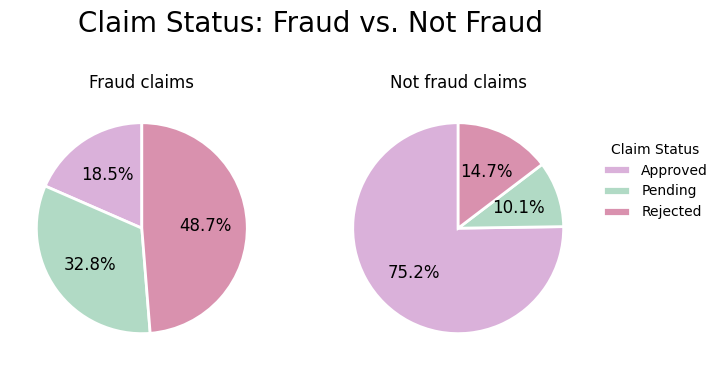

In [7]:
# Claim Status
counts = pd.crosstab(df["Claim_Status"], df["Is_Fraud"])
labels = counts.index.tolist()
colors = ["#DAB1DA", "#B1DAC5", "#D991AE", "#B1C5DA", "#F0E0F0", "#FFFFC5"][:len(labels)]

percents = df["Claim_Status"].value_counts(normalize=True) * 100
print(percents.round(2))

fig, axes = plt.subplots(1, 2, figsize=(8, 4.5))

for ax, (flag, name) in zip(axes, [(1, "Fraud claims"), (0, "Not fraud claims")]):
    ax.pie(counts[flag], colors=colors, startangle=90,
           autopct="%1.1f%%",
           wedgeprops=dict(edgecolor="white", linewidth=2),
           textprops=dict(color="black", fontsize=12))
    ax.set_title(name)

fig.suptitle("Claim Status: Fraud vs. Not Fraud", fontsize=20)
fig.legend(labels, title="Claim Status", loc="center left", bbox_to_anchor=(0.85, 0.6), frameon=False)
plt.subplots_adjust(right=0.85)
plt.show()

These pie charts compare the claim breakdown of Fraud and Not Fraud Claims. The pie chart on the left shows that out of the claims flagged for fraud, **18.5%** of the claims were approved, **48.7%** of them were rejected, and **32.8%** of them are pending. Similarily, the pie chart on the right shows that out of the claims not flagged for fraud, **75.2%** of the claims were approved, **14.7%** of them were rejected, and **10.1%** of them are pending. The difference in values shows that Claim Status is an important characteristic in determining insurance fraud.

As it can be seen, insurance claims that are claimed to be fraud are more likely to be rejected or pending when compared to insurance claims that aren't claimed to be fraud. This is also supported by the fact that while 70% of insurance claims are approved overall, that number cuts down to 18.5% when it comes to claims that are frauds.

Visit_Type
Outpatient    34.23
Emergency     33.68
Inpatient     32.09
Name: proportion, dtype: float64


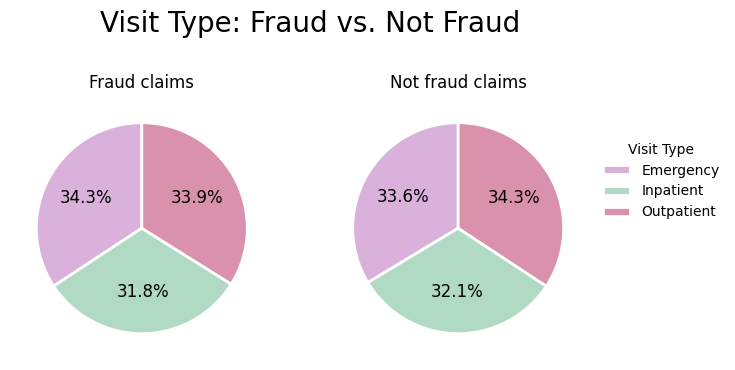

In [8]:
# Visit Type
counts = pd.crosstab(df["Visit_Type"], df["Is_Fraud"])
labels = counts.index.tolist()
colors = ["#DAB1DA", "#B1DAC5", "#D991AE", "#B1C5DA", "#F0E0F0", "#FFFFC5"][:len(labels)]   # one color per gender

percents = df["Visit_Type"].value_counts(normalize=True) * 100
print(percents.round(2))

fig, axes = plt.subplots(1, 2, figsize=(8, 4.5))

for ax, (flag, name) in zip(axes, [(1, "Fraud claims"), (0, "Not fraud claims")]):
    ax.pie(counts[flag], colors=colors, startangle=90,
           autopct="%1.1f%%",
           wedgeprops=dict(edgecolor="white", linewidth=2),
           textprops=dict(color="black", fontsize=12))
    ax.set_title(name)

fig.suptitle("Visit Type: Fraud vs. Not Fraud", fontsize=20)
fig.legend(labels, title="Visit Type", loc="center left", bbox_to_anchor=(0.85, 0.6), frameon=False)
plt.subplots_adjust(right=0.85)
plt.show()

These pie charts compare the visit type breakdown of Fraud and Not Fraud Claims. The pie chart on the left shows that out of the claims flagged for fraud, **34.3%** of them were filed by emergency patients, **33.9%** were filed outpatients, and **31.8%** were filed by inpatients. Similarily, the pie chart on the right shows that out of the claims not flagged for fraud, **33.6%** of them were filed by emergency patients, **34.3%** were filed outpatients, and **32.1%** were filed by inpatients The numbers are incredibly close, which means that Visit Type plays an incredibly small role in insurance fraud.

An aditional factor to note is that the visitors are pretty evenly split with their percents ranging from 32% to 34%, so there shouldn't be an overepresentation of any type of patient. In the real world, there might not be such an even split, so an overrepresentation of one type of patient needs to be taken into account when making conclusions.

Chronic_Condition_Flag
0    70.8
1    29.2
Name: proportion, dtype: float64


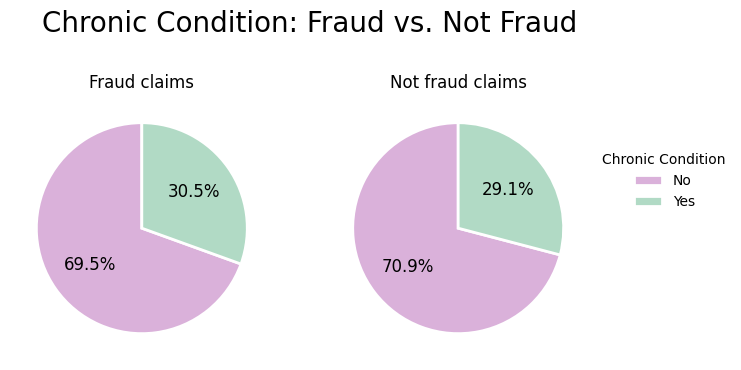

In [9]:
# Chronic Conditions
counts = pd.crosstab(df["Chronic_Condition_Flag"], df["Is_Fraud"])
labels = counts.index.tolist()
colors = ["#DAB1DA", "#B1DAC5"][:len(labels)]

percents = df["Chronic_Condition_Flag"].value_counts(normalize=True) * 100
print(percents.round(2))

fig, axes = plt.subplots(1, 2, figsize=(8, 4.5))

for ax, (flag, name) in zip(axes, [(1, "Fraud claims"), (0, "Not fraud claims")]):
    ax.pie(counts[flag], colors=colors, startangle=90,
           autopct="%1.1f%%",
           wedgeprops=dict(edgecolor="white", linewidth=2),
           textprops=dict(color="black", fontsize=12))
    ax.set_title(name)

fig.suptitle("Chronic Condition: Fraud vs. Not Fraud", fontsize=20)
fig.legend(["No", "Yes"], title="Chronic Condition", loc="center left", bbox_to_anchor=(0.85, 0.6), frameon=False)
plt.subplots_adjust(right=0.85)
plt.show()

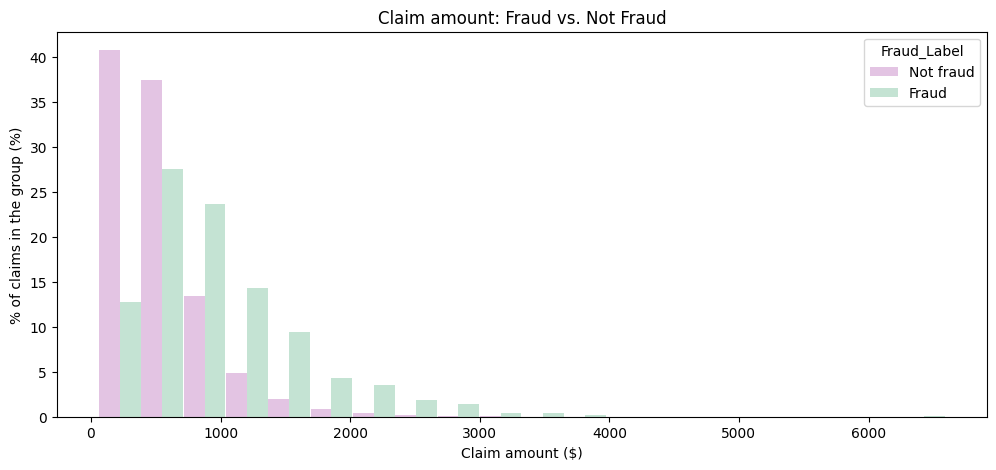

In [10]:
# For Patient_Age, Claim_Amount, Approved_Amount, Claim_Submission_Date, Days_Between_Service_And_Claim, Number_of_Claims_Per_Provider_Monthly
# and Length_of_Stay, I will make double bar histograms, since these have ranges of values where fraud claims and not fraud claims can be easily
# compared through bars rather than pie charts

import seaborn as sns
import matplotlib.pyplot as plt

df["Fraud_Label"] = df["Is_Fraud"].map({0: "Not fraud", 1: "Fraud"})

plt.figure(figsize=(12, 5))

sns.histplot(data = df, x = "Claim_Amount", hue = "Fraud_Label",
             stat= "percent", common_norm = False,
             multiple = "dodge", bins = 20, shrink=0.98, linewidth=0,
             palette = {"Not fraud": "#DAB1DA", "Fraud": "#B1DAC5"})

plt.title("Claim amount: Fraud vs. Not Fraud")
plt.xlabel("Claim amount ($)")
plt.ylabel("% of claims in the group (%)")
plt.show()

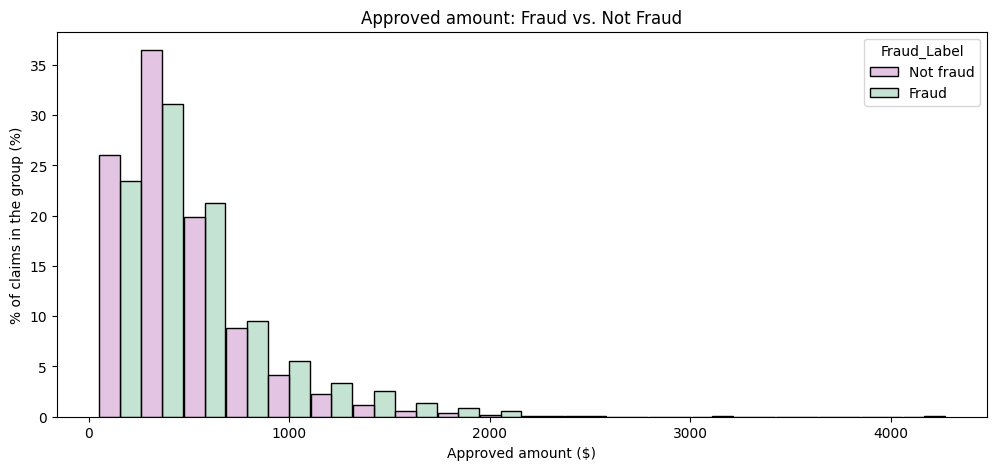

In [11]:
df["Fraud_Label"] = df["Is_Fraud"].map({0: "Not fraud", 1: "Fraud"})

plt.figure(figsize=(12, 5))

sns.histplot(data = df, x = "Approved_Amount", hue = "Fraud_Label",
             stat= "percent", common_norm = False,
             multiple = "dodge", bins = 20, shrink=0.98,
             palette = {"Not fraud": "#DAB1DA", "Fraud": "#B1DAC5"})

plt.title("Approved amount: Fraud vs. Not Fraud")
plt.xlabel("Approved amount ($)")
plt.ylabel("% of claims in the group (%)")
plt.show()

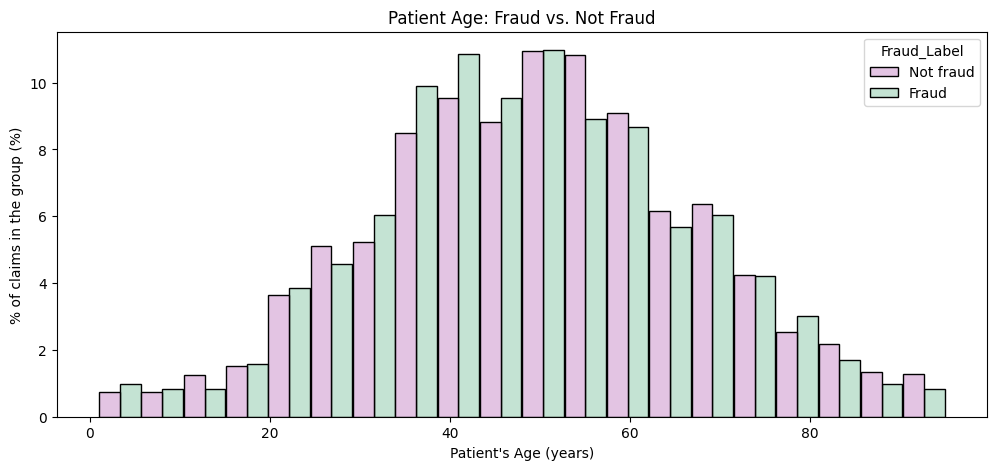

In [12]:
df["Fraud_Label"] = df["Is_Fraud"].map({0: "Not fraud", 1: "Fraud"})

plt.figure(figsize=(12, 5))

sns.histplot(data = df, x = "Patient_Age", hue = "Fraud_Label",
             stat= "percent", common_norm = False,
             multiple = "dodge", bins = 20, shrink=0.98,
             palette = {"Not fraud": "#DAB1DA", "Fraud": "#B1DAC5"})

plt.title("Patient Age: Fraud vs. Not Fraud")
plt.xlabel("Patient's Age (years)")
plt.ylabel("% of claims in the group (%)")
plt.show()

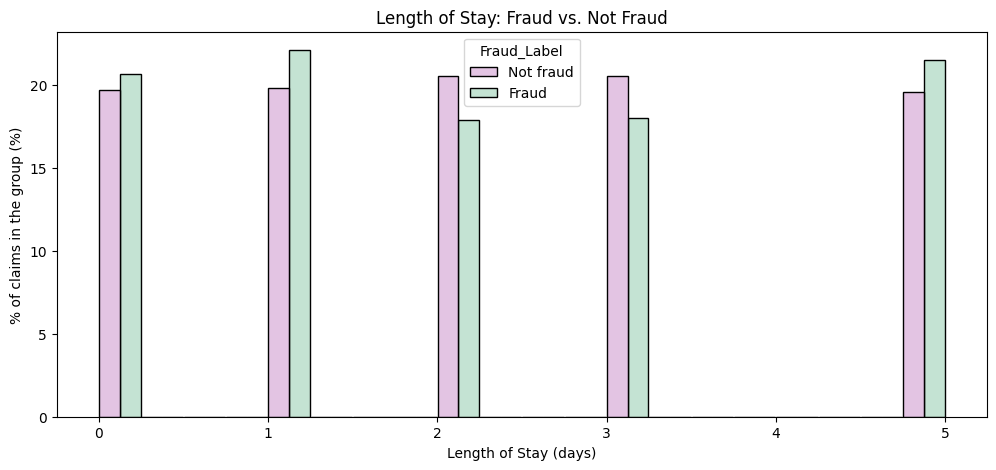

In [13]:
df["Fraud_Label"] = df["Is_Fraud"].map({0: "Not fraud", 1: "Fraud"})

plt.figure(figsize=(12, 5))

sns.histplot(data = df, x = "Length_of_Stay", hue = "Fraud_Label",
             stat= "percent", common_norm = False,
             multiple = "dodge", bins = 20, shrink=0.98,
             palette = {"Not fraud": "#DAB1DA", "Fraud": "#B1DAC5"})

plt.title("Length of Stay: Fraud vs. Not Fraud")
plt.xlabel("Length of Stay (days)")
plt.ylabel("% of claims in the group (%)")
plt.show()

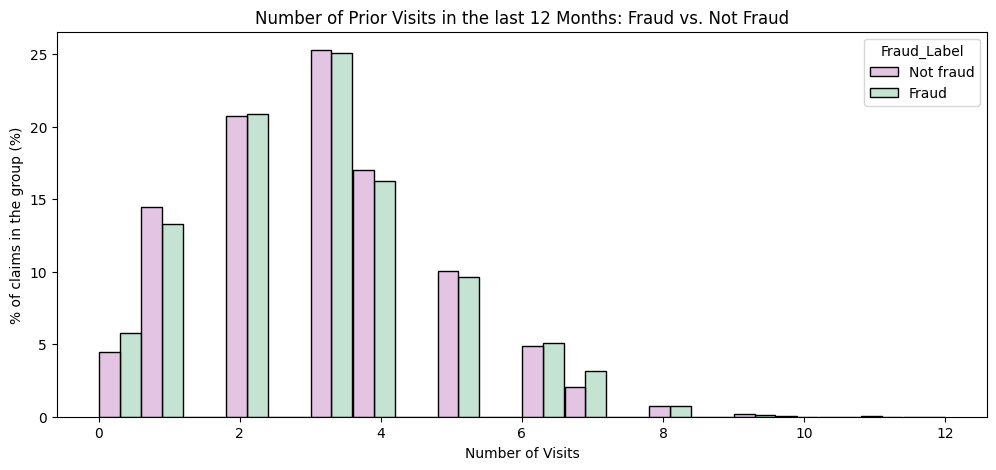

In [14]:
df["Fraud_Label"] = df["Is_Fraud"].map({0: "Not fraud", 1: "Fraud"})

plt.figure(figsize=(12, 5))

sns.histplot(data = df, x = "Prior_Visits_12m", hue = "Fraud_Label",
             stat= "percent", common_norm = False,
             multiple = "dodge", bins = 20, shrink=0.98,
             palette = {"Not fraud": "#DAB1DA", "Fraud": "#B1DAC5"})

plt.title("Number of Prior Visits in the last 12 Months: Fraud vs. Not Fraud")
plt.xlabel("Number of Visits")
plt.ylabel("% of claims in the group (%)")
plt.show()

---
## 5. Train/test split and baseline (REQUIRED)
A **baseline** is the simplest possible guess. If your model can't beat it, the model isn't adding much. Run the cell below as-is after filling in your features and target.
- For **classification**, the baseline always predicts the most common category.
- For **regression**, the baseline always predicts the average.

In [15]:
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyClassifier, DummyRegressor

# TODO: list your feature columns and your target column.
features = ["Patient_Age", "Patient_Gender", "Claim_Amount", "Insurance_Type",
    "Days_Between_Service_and_Claim", "Number_of_Claims_Per_Provider_Monthly",
    "Provider_Specialty", "Length_of_Stay", "Visit_Type",
    "Chronic_Condition_Flag", "Prior_Visits_12m"]
target = "Is_Fraud"

X = df[features]
y = df[target]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Classification baseline: always predict the most common category.
baseline = DummyClassifier(strategy="most_frequent")
# Regression baseline: delete the line above and use this one instead.
# baseline = DummyRegressor(strategy="mean")

baseline.fit(X_train, y_train)
baseline_pred = baseline.predict(X_test)
print("Baseline is ready. You'll compare it to your model in Section 7.")

Baseline is ready. You'll compare it to your model in Section 7.


---
## 6. Model (REQUIRED: at least one)
**Instructions:** Train at least one model you learned in the challenge (linear regression, logistic regression, decision tree, or random forest). Then fill in the summary.

#### Model 1
* **Model type:**
* **Features used:**
* **Why I chose this model:**

In [16]:
# TODO: train your model. Example for a decision tree:
# from sklearn.tree import DecisionTreeClassifier
# model = DecisionTreeClassifier(max_depth=4, random_state=42)
# model.fit(X_train, y_train)
# y_pred = model.predict(X_test)

#### Model 2, 3, ... (OPTIONAL)
Copy the Model 1 summary and code cell for each extra model.

---
## 7. Evaluation (REQUIRED)
**Instructions:** Pick one metric that fits your question and compare your model to the baseline.
- Classification: accuracy, precision, recall, or F1. If one category is rare (like fraud or default), accuracy can be misleading, so also look at recall or F1.
- Regression: RMSE or R-squared.

| Model | Metric: [name] |
|---|---|
| Baseline | [value] |
| Model 1 | [value] |

**Does your model beat the baseline? By how much, and does that difference matter for your question?**

[Text here]

In [17]:
from sklearn.metrics import accuracy_score, f1_score
# Regression: from sklearn.metrics import mean_squared_error, r2_score

print("Baseline accuracy:", round(accuracy_score(y_test, baseline_pred), 3))
print("Model accuracy:   ", round(accuracy_score(y_test, y_pred), 3))
# TODO (optional): add a second metric, e.g. f1_score(y_test, y_pred, pos_label=...)

Baseline accuracy: 0.923


NameError: name 'y_pred' is not defined

---
## 8. Fairness check (REQUIRED)
**Instructions:** Choose one column that describes a group of people (for example: sex, age group, race, marital status). Check whether your model performs equally well for each group. You don't need to include that column as a feature to check it.

**Group column I checked:** [column]

**What I found (2-3 sentences):** Is the model noticeably better or worse for any group? Why might that be, and who could be harmed?

[Text here]

In [ ]:
# TODO: set the column that describes the groups you want to compare.
group_col = "TODO_group_column"

groups = df.loc[X_test.index, group_col]
for g in groups.unique():
    mask = (groups == g).values
    acc = accuracy_score(y_test[mask], y_pred[mask])
    print(f"{g}: n = {mask.sum()}, accuracy = {acc:.3f}")

---
## 9. Limitations (REQUIRED)
**Instructions:** In 3-5 sentences: What can't your data or model tell you? What's missing from the data, and what would you do with more time?

[Text here]

---
## 10. Results (REQUIRED)
**Instructions:** In 5-10 sentences, explain what you found. Refer to your metric, the baseline, and your fairness check.

[Text here]

---
## 11. Conclusion and recommendations (REQUIRED)
**Instructions:** In 5-8 sentences: What should a bank, lender, regulator, or customer do with your findings?

[Text here]

---
## 12. AI-use log (REQUIRED)
**Instructions:** List each way you used AI tools (chatbots, code assistants, etc.). If you didn't use any, write "None."

| Tool | What I used it for | How I checked the output |
|---|---|---|
| Gemini | I was confused as to how to import the CSV file | It told me how to do that, and how I was supposed to click the file icon on the side |
| Gemini | It was showing an error when dropping columns | It told me to use error = 'ignore' to prevent removing the columns too early |
| Claude | For some reason, for the double bar histogram, the legend was overlapping with the bars and I wasn't sure how to fix it | It gave me a plt.legend code that let me manually adjust the legend |
| Claude | I saw this (flag, name) part online, but it wasn't working no matter what I tried | It showed me how to use it, and turns out I was supposed use in zip, which I wasn't doing |

---
## 13. Slides, video, and references (REQUIRED)
- **Slides (15 or fewer):** [link]
- **Video (5-7 minutes):** [link]

**References:** Links to any articles or resources you used to interpret results or make recommendations.
1. [Reference 1 with link]
2. [...]

---
## Make it shine (OPTIONAL)
Ideas if you have extra time: compare 2-3 models, tune a model (for example, `max_depth`), show feature importance, combine two datasets, or add a confusion matrix. See "Tips to Make Your Project Shine" on the challenge homepage.